# GPT: Generative Pre-Training (Radford et al., 2018)

*Improving Language Understanding by Generative Pre-Training* made a simple bet.
Labelled data is scarce and unlabelled text is nearly free, so first train a
transformer to **predict the next token** on a large pile of books. Then adapt
it to each real task with a small labelled set and a thin output layer.

The model is the Transformer decoder from
[Attention Is All You Need](/how-models-work/attention-is-all-you-need/) with the
encoder and cross-attention removed. The method is two stages, and every GPT
since has kept that shape:

1. **Unsupervised pre-training**: maximise $\sum_i \log P(u_i \mid u_{i-k}, \dots, u_{i-1})$ on raw text.
2. **Supervised fine-tuning**: add a linear layer, train on the task, and keep
   the language-modelling loss as an auxiliary term.

This page trains a tiny GPT for real, generates from it, checks the causal mask,
counts GPT-1's 117M parameters from its configuration, and tests the paper's
central claim: features learned by next-token prediction transfer to a task
the model was never trained on.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


print("helpers ready")

helpers ready


## 1. A corpus with structure to learn

GPT-1 pre-trained on BooksCorpus, about 7,000 unpublished books. Here the
corpus is generated from a small grammar instead: subjects, verbs, objects,
places and connectives combined at random. It has real structure, such as
agreement, word order and punctuation, and it is small enough to learn in
seconds on a CPU.

The model reads **characters**, not BPE tokens, so the vocabulary is tiny and
nothing hides in the tokenizer.

In [2]:
banner("BUILD THE CORPUS")
rng = np.random.default_rng(1)
SUBJ = ["the cat", "the dog", "a bird", "my sister", "the old man", "a child", "the teacher"]
VERB = ["sees", "likes", "finds", "follows", "watches", "helps"]
OBJ = ["the ball", "a red box", "the river", "her friend", "the small house", "a green tree"]
PLACE = ["in the park", "near the river", "at home", "after school", "in the morning"]
CONJ = ["and then", "but later", "so"]


def sentence(r):
    s = f"{r.choice(SUBJ)} {r.choice(VERB)} {r.choice(OBJ)}"
    if r.random() < 0.6:
        s += f" {r.choice(PLACE)}"
    if r.random() < 0.3:
        s += f" {r.choice(CONJ)} {r.choice(SUBJ)} {r.choice(VERB)} {r.choice(OBJ)}"
    return s + ". "


text = "".join(sentence(rng) for _ in range(2600))
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
data = torch.tensor([stoi[c] for c in text])
split = int(0.9 * len(data))
train_d, val_d = data[:split], data[split:]
print(f"  {len(text):,} characters, vocabulary of {len(chars)}: {''.join(chars)!r}")
print(f"  sample: {text[:150]!r}")

step("Baselines: how predictable is the next character without a neural net?")
cnt = Counter(text[:split])
p_uni = np.array([cnt[c] for c in chars], float); p_uni /= p_uni.sum()
H_uni = -np.mean([np.log(p_uni[stoi[c]]) for c in text[split:]])
big = Counter(zip(text[:split], text[1:split]))
prev_tot = Counter(text[:split - 1])
V_ = len(chars)
H_bi = -np.mean([np.log((big[(a, b)] + 1) / (prev_tot[a] + V_))
                 for a, b in zip(text[split:], text[split + 1:])])
print(f"  unigram  (letter frequencies only):   {H_uni:.3f} nats per character")
print(f"  bigram   (previous character only):   {H_bi:.3f} nats per character")

  BUILD THE CORPUS
  119,257 characters, vocabulary of 25: ' .abcdefghiklmnoprstuvwxy'
  sample: 'my sister follows the small house in the morning. the dog likes a green tree. a bird follows her friend in the morning. a child watches a red box. the'

Baselines: how predictable is the next character without a neural net?
------------------------------------------------------------------------------
  unigram  (letter frequencies only):   2.747 nats per character
  bigram   (previous character only):   1.615 nats per character


## 2. A decoder-only transformer, and its training objective

The architecture is the GPT-1 recipe at toy scale: token and *learned* position
embeddings, a stack of blocks (masked self-attention then a feed-forward layer,
each wrapped in a residual connection and layer norm), and an output layer that
shares its weights with the token embedding.

The loss is the paper's $L_1$: the average negative log-probability of each
next character. One forward pass over a 64-character window gives 64
predictions at once, because the causal mask stops each position from seeing
its future.

  PRE-TRAIN WITH THE LANGUAGE-MODELLING LOSS
  parameters: 344,064
  step    1:  train 3.312   validation 3.004 nats/char
  step  100:  train 1.085   validation 1.098 nats/char
  step  300:  train 0.305   validation 0.304 nats/char
  step  700:  train 0.262   validation 0.265 nats/char

Compare with the baselines
------------------------------------------------------------------------------
  unigram 2.747   bigram 1.615   tiny GPT 0.265
  [PASS] the transformer beats the bigram model on held-out text


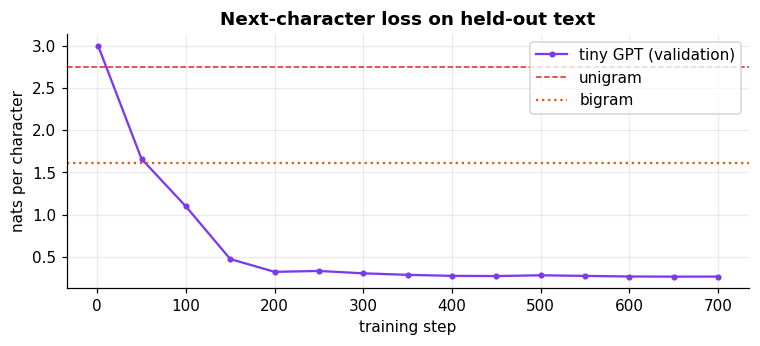

In [3]:
class Block(nn.Module):
    def __init__(self, d, h, T):
        super().__init__()
        self.h = h
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.register_buffer("mask", torch.tril(torch.ones(T, T)).bool())

    def forward(self, x):
        B, T, d = x.shape
        q, k, v = self.qkv(x).split(d, 2)
        q, k, v = (t.view(B, T, self.h, d // self.h).transpose(1, 2) for t in (q, k, v))
        att = (q @ k.transpose(-2, -1)) / (d // self.h) ** 0.5
        att = att.masked_fill(~self.mask[:T, :T], float("-inf")).softmax(-1)
        y = (att @ v).transpose(1, 2).reshape(B, T, d)
        x = self.ln1(x + self.proj(y))          # post-LN, as in GPT-1
        return self.ln2(x + self.ff(x))


class TinyGPT(nn.Module):
    def __init__(self, V, d=96, h=4, L=3, T=64):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(T, d)
        self.blocks = nn.ModuleList([Block(d, h, T) for _ in range(L)])
        for m in self.modules():                      # GPT-1 initialises with N(0, 0.02)
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0.0, 0.02)
            if isinstance(m, nn.Linear):
                nn.init.zeros_(m.bias)

    def hidden(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        for b in self.blocks:
            x = b(x)
        return x

    def forward(self, idx):
        return self.hidden(idx) @ self.tok.weight.T     # tied output layer


CTX = 64
def batch(src, n=48):
    ix = torch.randint(0, len(src) - CTX - 1, (n,))
    return torch.stack([src[i:i + CTX] for i in ix]), torch.stack([src[i + 1:i + CTX + 1] for i in ix])


banner("PRE-TRAIN WITH THE LANGUAGE-MODELLING LOSS")
model = TinyGPT(V_)
print(f"  parameters: {sum(p.numel() for p in model.parameters()):,}")
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
hist = []
for it in range(1, 701):
    xb, yb = batch(train_d)
    loss = F.cross_entropy(model(xb).reshape(-1, V_), yb.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 50 == 0 or it == 1:
        with torch.no_grad():
            xv, yv = batch(val_d, 200)
            vl = F.cross_entropy(model(xv).reshape(-1, V_), yv.reshape(-1)).item()
        hist.append((it, loss.item(), vl))
        if it in (1, 100, 300, 700):
            print(f"  step {it:>4}:  train {loss.item():.3f}   validation {vl:.3f} nats/char")
final_val = hist[-1][2]
step("Compare with the baselines")
print(f"  unigram {H_uni:.3f}   bigram {H_bi:.3f}   tiny GPT {final_val:.3f}")
check("the transformer beats the bigram model on held-out text", final_val < H_bi)

h_ = np.array(hist)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(h_[:, 0], h_[:, 2], "o-", ms=3, color="#7c3aed", label="tiny GPT (validation)")
ax.axhline(H_uni, color="#dc2626", ls="--", lw=1, label="unigram")
ax.axhline(H_bi, color="#ea580c", ls=":", lw=1.5, label="bigram")
ax.set_xlabel("training step"); ax.set_ylabel("nats per character")
ax.set_title("Next-character loss on held-out text"); ax.legend()

## 3. The causal mask, verified on the trained model

The loss above is valid only if position $t$'s prediction does not depend on
characters after $t$. Otherwise the model could read the answer. The check:
change the last half of an input and confirm that the first half's outputs do
not move at all.

In [4]:
banner("THE FUTURE CANNOT LEAK INTO THE PAST")
model.eval()
xb, _ = batch(val_d, 1)
x2 = xb.clone(); x2[0, 32:] = torch.randint(0, V_, (32,))
with torch.no_grad():
    a, b = model(xb), model(x2)
d_early = (a[0, :32] - b[0, :32]).abs().max().item()
d_late = (a[0, 32:] - b[0, 32:]).abs().max().item()
print(f"  max change in logits at positions 0-31:  {d_early:.2e}")
print(f"  max change in logits at positions 32-63: {d_late:.2f}")
check("earlier predictions untouched by later characters", d_early < 1e-5)

  THE FUTURE CANNOT LEAK INTO THE PAST
  max change in logits at positions 0-31:  0.00e+00
  max change in logits at positions 32-63: 21.91
  [PASS] earlier predictions untouched by later characters


## 4. Generation is the training objective, run in a loop

To generate, predict a distribution for the next character, pick one, append
it, and repeat. The animation below runs exactly that on the model trained
above. The bars are its real top-5 probabilities at each step, sampled with
temperature 0.7.

In [5]:
banner("SAMPLING FROM THE TRAINED MODEL")
g = torch.Generator().manual_seed(4)
prompt = "the dog "
seq = [stoi[c] for c in prompt]
steps_ = []
with torch.no_grad():
    for _ in range(22):
        logits = model(torch.tensor([seq[-CTX:]]))[0, -1] / 0.7
        p = logits.softmax(-1)
        top = torch.topk(p, 5)
        nxt = torch.multinomial(p, 1, generator=g).item()
        steps_.append(([itos[i] for i in top.indices.tolist()], top.values.tolist(), itos[nxt],
                       p[nxt].item()))
        seq.append(nxt)
gen = "".join(itos[i] for i in seq)
print(f"  prompt: {prompt!r}")
print(f"  output: {gen!r}")
for k in range(6):
    cands = ", ".join(f"{c!r} {v:.2f}" for c, v in zip(steps_[k][0], steps_[k][1]))
    print(f"  step {k+1}: top-5 = [{cands}]  ->  picked {steps_[k][2]!r}")

with torch.no_grad():
    longer = []
    for t0 in ["a child ", "my sister likes "]:
        sq = [stoi[c] for c in t0]
        for _ in range(60):
            p = (model(torch.tensor([sq[-CTX:]]))[0, -1] / 0.7).softmax(-1)
            sq.append(torch.multinomial(p, 1, generator=g).item())
        longer.append("".join(itos[i] for i in sq))
step("Two longer samples")
for s_ in longer:
    print(f"  {s_!r}")

  SAMPLING FROM THE TRAINED MODEL
  prompt: 'the dog '
  output: 'the dog watches her friend aft'
  step 1: top-5 = ['f' 0.41, 'h' 0.18, 'l' 0.17, 'w' 0.14, 's' 0.09]  ->  picked 'w'
  step 2: top-5 = ['a' 1.00, 's' 0.00, 'o' 0.00, 't' 0.00, 'n' 0.00]  ->  picked 'a'
  step 3: top-5 = ['t' 1.00, 'f' 0.00, 'c' 0.00, 'n' 0.00, ' ' 0.00]  ->  picked 't'
  step 4: top-5 = ['c' 1.00, 'b' 0.00, 't' 0.00, 'h' 0.00, ' ' 0.00]  ->  picked 'c'
  step 5: top-5 = ['h' 1.00, 's' 0.00, 'f' 0.00, 'a' 0.00, 'w' 0.00]  ->  picked 'h'
  step 6: top-5 = ['e' 1.00, ' ' 0.00, 'k' 0.00, 'h' 0.00, 'i' 0.00]  ->  picked 'e'

Two longer samples
------------------------------------------------------------------------------
  'a child helps her friend. the old man helps the small house. the dog'
  'my sister likes the river near the river. the old man follows her friend in '


In [6]:
def gen_scene():
    sc = Scene(720, 380, dur=0.8 + len(steps_) * 0.55 + 0.6,
               caption="Autoregressive generation from the tiny GPT trained above (temperature 0.7)",
               poster=0.8 + 12 * 0.55)
    sc.text(30, 36, "context", size=13, fill="muted", anchor="start")
    cw = 21
    x0 = 30
    for i, c in enumerate(prompt):
        sc.text(x0 + i * cw + 10, 72, c if c != " " else "·", size=20, fill="text", mono=True)
    sc.text(30, 140, "next-character probabilities", size=13, fill="muted", anchor="start")
    bars, labs, vals = [], [], []
    for r in range(5):
        y = 160 + r * 36
        labs.append(sc.text(60, y + 13, "", size=16, fill="amber", mono=True))
        bars.append(sc.rect(90, y, 0, 26, fill="violet", rx=4))
        vals.append(sc.num(100, y + 13, 0, dec=2, size=13, fill="text", anchor="start"))
    for k, (cands, probs, pick, pp) in enumerate(steps_):
        t0 = 0.8 + k * 0.55
        for r in range(5):
            w = probs[r] * 480
            labs[r].set(t0, s=repr(cands[r])[1:-1] if cands[r] != " " else "␣")
            col = "green" if cands[r] == pick else "violet"
            bars[r].to(t0, t0 + 0.25, w=w, fill=col, ease="out")
            vals[r].to(t0, t0 + 0.25, v=probs[r], x=96 + w + 8)
        pos = len(prompt) + k
        x = x0 + pos * cw + 10 if pos < 32 else x0 + (pos - 32) * cw + 10
        y = 72 if pos < 32 else 104
        ch = sc.text(x, y - 18, pick if pick != " " else "·", size=20, fill="green", mono=True, opacity=0)
        ch.to(t0 + 0.3, t0 + 0.5, opacity=1, y=y, ease="out")
        ch.to(t0 + 0.55, t0 + 0.8, fill="text")
    sc.beat(0.0, "Feed the context in; the model returns a probability for every character.")
    sc.beat(0.8 + 3 * 0.55, "Sample one (green), append it, and feed the longer context back in.")
    sc.beat(0.8 + 10 * 0.55, "Spaces and word endings come out near-certain; word choices are spread out.")
    return sc

gen_scene()

<motion scene: Autoregressive generation from the tiny GPT trained above (temperature 0.7) (47 elements, 13.5s)>

## 5. GPT-1's size, counted from its configuration

The paper's model: 12 decoder blocks, $d = 768$, 12 heads, feed-forward width
3,072, learned position embeddings for 512 positions, and a BPE vocabulary with
40,000 merges (40,478 tokens in the released model). The output layer is tied
to the token embedding, so it adds no parameters.

In [7]:
banner("COUNTING GPT-1")
V, d, L, T, ff = 40478, 768, 12, 512, 3072
emb = V * d + T * d
attn = d * 3 * d + 3 * d + d * d + d
mlp = d * ff + ff + ff * d + d
ln = 2 * 2 * d
per_block = attn + mlp + ln
total = emb + L * per_block
print(f"  token embedding   {V:,} x {d}            = {V*d:>12,}")
print(f"  position emb.     {T} x {d}               = {T*d:>12,}")
print(f"  attention / block 4*{d}^2 + 4*{d}        = {attn:>12,}")
print(f"  MLP / block       2*{d}*{ff} + {ff} + {d}   = {mlp:>12,}")
print(f"  layer norms/block 2 x (gain + bias)       = {ln:>12,}")
print(f"  12 blocks                                 = {L*per_block:>12,}")
print(f"  total                                     = {total:>12,}  ({total/1e6:.1f}M)")
print(f"\n  The usual figure is 117M; the GPT-2 paper lists its smallest model, the")
print(f"  same shape as GPT-1, at that size. Count here: {total/1e6:.1f}M.")
step("Our tiny model, counted the same way vs PyTorch")
d_, L_, T_, ff_ = 96, 3, 64, 384
mine = V_ * d_ + T_ * d_ + L_ * (4 * d_ * d_ + 4 * d_ + 2 * d_ * ff_ + ff_ + d_ + 4 * d_)
check(f"formula {mine:,} == PyTorch {sum(p.numel() for p in model.parameters()):,}",
      mine == sum(p.numel() for p in model.parameters()))

  COUNTING GPT-1
  token embedding   40,478 x 768            =   31,087,104
  position emb.     512 x 768               =      393,216
  attention / block 4*768^2 + 4*768        =    2,362,368
  MLP / block       2*768*3072 + 3072 + 768   =    4,722,432
  layer norms/block 2 x (gain + bias)       =        3,072
  12 blocks                                 =   85,054,464
  total                                     =  116,534,784  (116.5M)

  The usual figure is 117M; the GPT-2 paper lists its smallest model, the
  same shape as GPT-1, at that size. Count here: 116.5M.

Our tiny model, counted the same way vs PyTorch
------------------------------------------------------------------------------
  [PASS] formula 344,064 == PyTorch 344,064


## 6. Fine-tuning: one model, many task formats

The second stage adds one linear layer $W_y$ on the final hidden state of the
last token and trains

$$L_3 = L_2(\text{task}) + \lambda\, L_1(\text{language modelling}), \qquad \lambda = 0.5$$

Keeping $L_1$ as an auxiliary loss improved generalisation and sped up
convergence on the larger datasets.

The paper's other contribution is how to feed **structured** inputs to a model
that only reads sequences. Instead of task-specific architectures, every task
becomes one or more token sequences with start, delimiter and extract tokens:

In [8]:
def formats_scene():
    sc = Scene(720, 400, dur=11.5, caption="Input transformations for fine-tuning (after the paper's Figure 1)",
               poster=10.5)
    rows = [
        ("Classification", [("Start", "muted"), ("Text", "cyan"), ("Extract", "muted")], 1),
        ("Entailment", [("Start", "muted"), ("Premise", "cyan"), ("Delim", "muted"), ("Hypothesis", "violet"),
                        ("Extract", "muted")], 1),
        ("Similarity", [("Start", "muted"), ("Text 1", "cyan"), ("Delim", "muted"), ("Text 2", "violet"),
                        ("Extract", "muted")], 2),
        ("Multiple choice", [("Start", "muted"), ("Context", "cyan"), ("Delim", "muted"), ("Answer k", "amber"),
                             ("Extract", "muted")], 3),
    ]
    widths = {"Start": 46, "Delim": 46, "Extract": 56}
    t = 0.5
    for r, (name, toks, kind) in enumerate(rows):
        y = 40 + r * 90
        sc.text(18, y + 16, name, size=14, fill="text", anchor="start", weight=700, opacity=0).fade_in(t)
        x = 140
        for j, (lab, col) in enumerate(toks):
            w = widths.get(lab, 76)
            box = sc.rect(x + 40, y, w, 32, fill=mix("panel", col, 0.35), stroke=col, sw=1.5, rx=6, opacity=0)
            box.to(t + 0.15 * j, t + 0.15 * j + 0.45, x=x, opacity=1, ease="back")
            tx = sc.text(x + 40 + w / 2, y + 16, lab, size=11, fill="text", opacity=0)
            tx.to(t + 0.15 * j, t + 0.15 * j + 0.45, x=x + w / 2, opacity=1, ease="back")
            x += w + 6
        ta = t + 0.15 * len(toks) + 0.3
        sc.arrow(x + 4, y + 16, x + 30, y + 16, stroke="muted", sw=2, head=8, opacity=0).fade_in(ta, 0.3)
        tb = sc.rect(x + 34, y, 82, 32, fill="panel", stroke="green", sw=1.5, rx=6, opacity=0)
        tb.fade_in(ta + 0.1, 0.3)
        sc.text(x + 75, y + 16, "Transformer", size=11, fill="green", opacity=0).fade_in(ta + 0.1, 0.3)
        sc.arrow(x + 118, y + 16, x + 140, y + 16, stroke="muted", sw=2, head=8, opacity=0).fade_in(ta + 0.3, 0.3)
        note = {1: "Linear", 2: "+ both orders", 3: "softmax over k"}[kind]
        sc.text(x + 146, y + 16, note, size=11, fill="amber", anchor="start", opacity=0).fade_in(ta + 0.4, 0.3)
        if kind == 2:
            sc.text(150, y + 50, "run twice, Text 1/Text 2 swapped; add the two final states", size=11,
                    fill="muted", anchor="start", opacity=0).fade_in(ta + 0.5)
        if kind == 3:
            sc.text(150, y + 50, "one sequence per answer; a score each; softmax across answers", size=11,
                    fill="muted", anchor="start", opacity=0).fade_in(ta + 0.5)
        t = ta + 1.3
    sc.beat(0.0, "No new architecture per task: only a new way of writing the input.")
    sc.beat(3.0, "Two sentences are joined with a delimiter token the model learns during fine-tuning.")
    sc.beat(5.6, "Similarity has no natural order, so both orders are processed and combined.")
    sc.beat(8.2, "Multiple choice scores each (context, answer) pair independently.")
    return sc

formats_scene()

<motion scene: Input transformations for fine-tuning (after the paper's Figure 1) (62 elements, 11.5s)>

## 7. Does pre-training transfer? A test on the tiny model

The paper's claim is that next-token prediction teaches features useful for
tasks the model never saw. A small version of that test: tell a **grammatical**
sentence from the same words in **shuffled order**. A bag-of-characters
classifier cannot do this, because both versions contain exactly the same
characters.

Two transfer methods, each given only 40 labelled examples:

* **Linear probe**: freeze the model, take the final hidden state at the last
  token (the paper's *Extract* position), and fit logistic regression on top.
  This is the cheapest form of fine-tuning.
* **Zero-shot**: no training at all. Score each sentence by its average LM loss
  and call the lower-loss one grammatical. The paper reports zero-shot
  heuristics like this too.

The control is the same architecture with random weights.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

banner("TRANSFER WITH 40 LABELLED EXAMPLES")
r2 = np.random.default_rng(7)


def make_pair(r):
    s_ = sentence(r).strip()
    w = s_[:-1].split()
    sh = w[:]
    while sh == w:
        r.shuffle(sh)
    return s_, " ".join(sh) + "."


def feats(m, sents):
    out = []
    with torch.no_grad():
        for s_ in sents:
            idx = torch.tensor([[stoi[c] for c in s_[:CTX]]])
            out.append(m.hidden(idx)[0, -1].numpy())     # state at the final token
    return np.array(out)


def lm_loss(m, s_):
    idx = torch.tensor([[stoi[c] for c in s_[:CTX]]])
    with torch.no_grad():
        return F.cross_entropy(m(idx[:, :-1])[0], idx[0, 1:]).item()


train_pairs = [make_pair(r2) for _ in range(20)]
test_pairs = [make_pair(r2) for _ in range(300)]
Xtr = [s_ for p in train_pairs for s_ in p]; ytr = [1, 0] * 20
Xte = [s_ for p in test_pairs for s_ in p]; yte = [1, 0] * 300
print(f"  example pair:  {test_pairs[0][0]!r}")
print(f"                 {test_pairs[0][1]!r}")

torch.manual_seed(123)
random_model = TinyGPT(V_).eval()
res = {}
for name, m in [("pre-trained", model), ("random init", random_model)]:
    sc_ = StandardScaler().fit(feats(m, Xtr))
    clf = LogisticRegression(C=1.0, max_iter=5000).fit(sc_.transform(feats(m, Xtr)), ytr)
    probe = clf.score(sc_.transform(feats(m, Xte)), yte)
    zs = np.mean([lm_loss(m, a) < lm_loss(m, b) for a, b in test_pairs])
    res[name] = (probe, zs)
    print(f"  {name:<12}  linear probe accuracy {probe:.3f}   zero-shot pair accuracy {zs:.3f}")
print(f"  chance level: 0.500")
check("pre-trained features beat random features on the probe",
      res["pre-trained"][0] > res["random init"][0])
check("zero-shot LM scoring picks the grammatical sentence far above chance",
      res["pre-trained"][1] > 0.8)

  TRANSFER WITH 40 LABELLED EXAMPLES
  example pair:  'the old man likes a red box near the river.'
                 'the red river old the near a likes box man.'
  pre-trained   linear probe accuracy 0.610   zero-shot pair accuracy 1.000
  random init   linear probe accuracy 0.508   zero-shot pair accuracy 0.623
  chance level: 0.500
  [PASS] pre-trained features beat random features on the probe
  [PASS] zero-shot LM scoring picks the grammatical sentence far above chance


The two methods give very different results, and the difference is worth
reading closely.

* **Zero-shot is decisive.** The pre-trained model gives the grammatical version
  the lower loss in every one of the 300 test pairs. With random weights that
  happens about 60% of the time. The signal sits directly in the
  language-modelling objective, because a shuffled sentence is simply less
  probable text.
* **The linear probe is a modest win**: about 61% against 51%. Forty labels and
  one frozen 96-dimensional state, read at the final full stop, carry only part
  of what the LM loss knows. The paper fine-tuned the *whole* model on
  thousands of examples, which is a much stronger form of transfer than a frozen
  probe.

## Summary

* GPT-1 = Transformer decoder + next-token prediction on unlabelled books, then
  supervised fine-tuning with one added linear layer, keeping the LM loss as an
  auxiliary term ($\lambda = 0.5$).
* The causal mask turns one forward pass into a prediction at every position,
  and generation is the same prediction applied in a loop.
* Structured tasks become sequences with start, delimiter and extract tokens,
  so no task needs its own architecture.
* At GPT-1's configuration the parameter count comes to about 116.5M, matching
  the familiar "117M".
* Even at toy scale, next-token pre-training transfers. With no task training
  at all, its LM loss picks the grammatical sentence 100% of the time, against
  about 60% for random weights. A frozen linear probe on 40 labels gains less,
  which is why the paper fine-tunes the whole network.
* GPT-2 (2019) and GPT-3 (2020) kept this recipe, scaled it up, and found that
  with enough scale the fine-tuning stage could often be replaced by a prompt.